# 4 Wavelet-Based Speech Denoising and Audio Signal Processing

## 4.5 Speech Data Source
### 4.5.1 Data Acquisition

Loading existing files from ./data/ ...


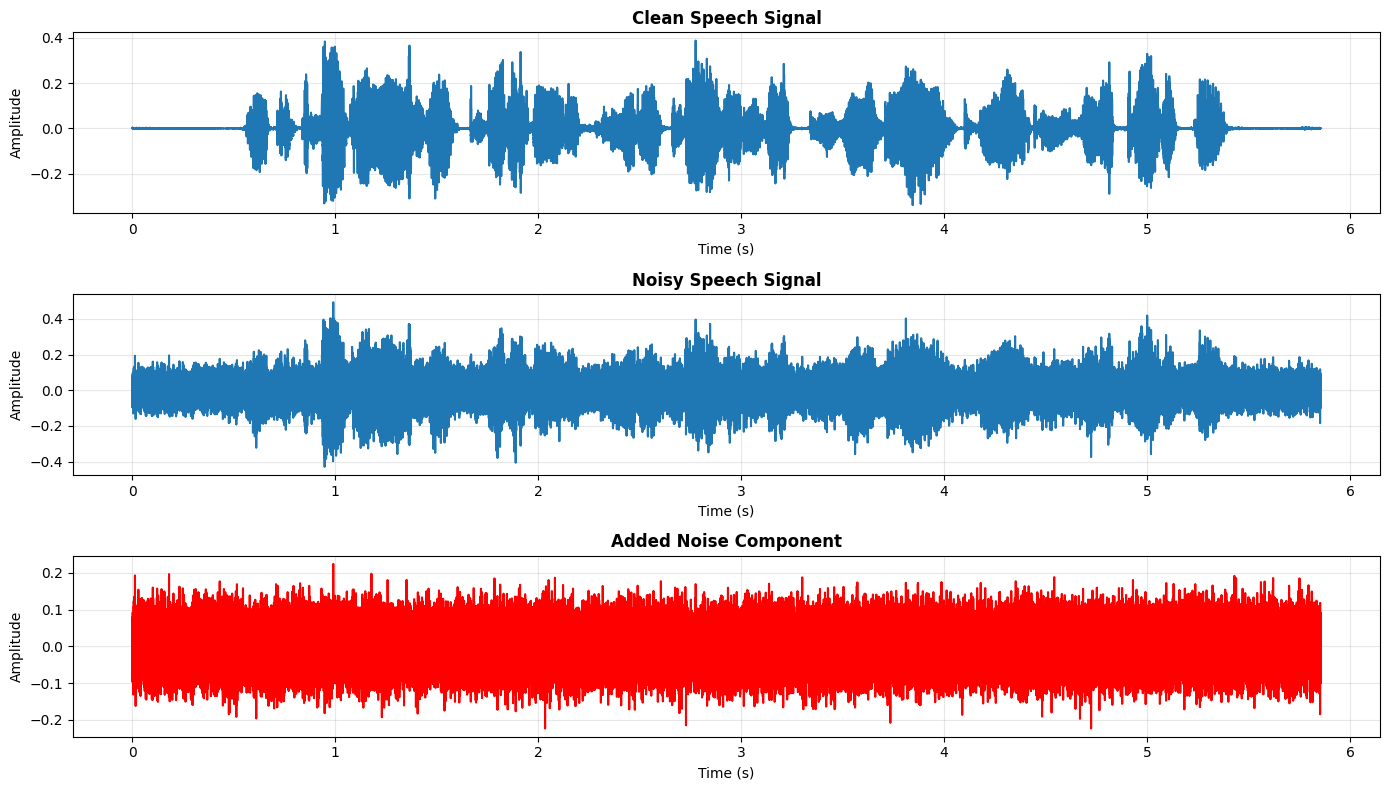


Data preparation complete!


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
from datasets import load_dataset

# Ensure ./data directory exists
os.makedirs("data", exist_ok=True)

clean_path = "./data/clean_speech.wav"
noisy_path = "./data/noisy_speech.wav"

if os.path.exists(clean_path) and os.path.exists(noisy_path):
    print("Loading existing files from ./data/ ...")
    clean_speech, sr = librosa.load(clean_path, sr=None)
    noisy_speech, _ = librosa.load(noisy_path, sr=None)
else:
    print("Downloading clean speech from LibriSpeech dataset...")
    
    # Load dataset without decoding audio
    from datasets import Audio
    dataset = load_dataset(
        "hf-internal-testing/librispeech_asr_dummy",
        "clean",
        split="validation",
        streaming=False
    )
    
    # Disable automatic audio decoding
    dataset = dataset.cast_column("audio", Audio(decode=False))
    
    # Get the audio info - it contains the bytes
    audio_info = dataset[0]["audio"]
    
    # The 'bytes' field contains the actual audio data
    audio_bytes = audio_info["bytes"]
    
    # Write bytes to a temporary file and load it
    import tempfile
    with tempfile.NamedTemporaryFile(delete=False, suffix='.flac') as tmp_file:
        tmp_file.write(audio_bytes)
        tmp_path = tmp_file.name
    
    try:
        # Load with librosa
        clean_speech, sr = librosa.load(tmp_path, sr=None)
    finally:
        # Clean up temporary file
        os.unlink(tmp_path)

    # Generate noise
    np.random.seed(42)
    noise = np.random.normal(0, 0.05, len(clean_speech))
    noisy_speech = clean_speech + noise

    # Save to ./data/
    sf.write(clean_path, clean_speech, sr)
    sf.write(noisy_path, noisy_speech, sr)
    print(f"Saved clean and noisy speech to {clean_path} and {noisy_path}")

# Plot signals
fig, axes = plt.subplots(3, 1, figsize=(14, 8))

axes[0].plot(np.arange(len(clean_speech))/sr, clean_speech)
axes[0].set_title("Clean Speech Signal", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True, alpha=0.3)

axes[1].plot(np.arange(len(noisy_speech))/sr, noisy_speech)
axes[1].set_title("Noisy Speech Signal", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, alpha=0.3)

noise_component = noisy_speech - clean_speech
axes[2].plot(np.arange(len(noise_component))/sr, noise_component, color='red')
axes[2].set_title("Added Noise Component", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Amplitude")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("./output/speech_noise_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

print("\nData preparation complete!")

### 4.5.2 Wavelet Denoising Implementation


Applying wavelet denoising...


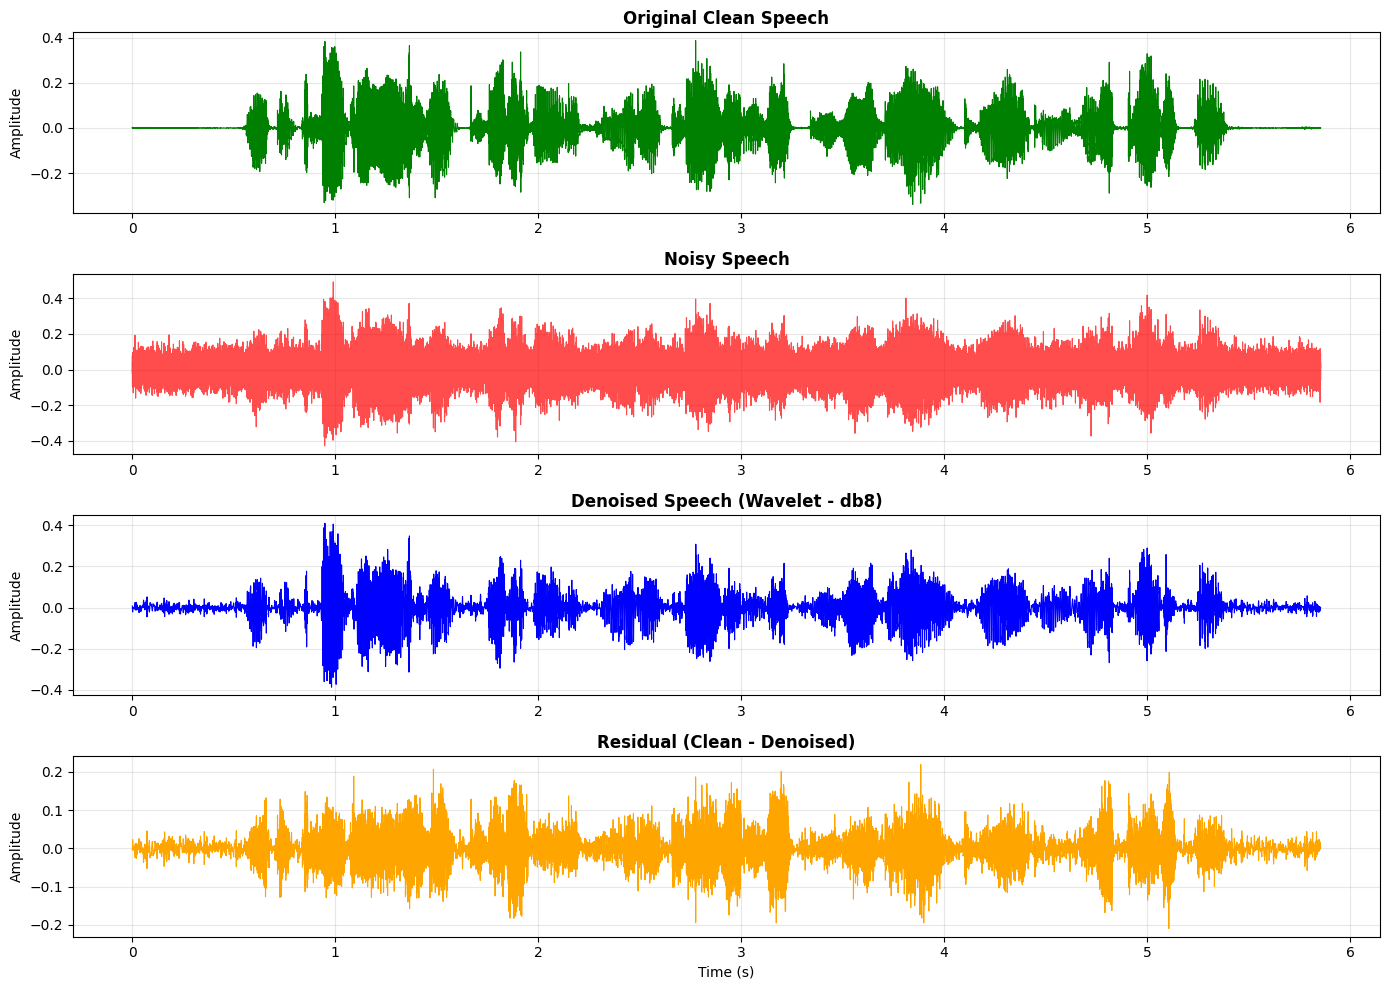

Wavelet denoising complete!


In [ ]:
import pywt
import numpy as np
import matplotlib.pyplot as plt


def wavelet_denoise(signal_data, wavelet='db4', level=5, threshold_multiplier=0.2):
    """
    Wavelet-based speech denoising with adjustable threshold multiplier.
    
    Parameters:
    - signal_data: Input noisy signal (1D array)
    - wavelet: Wavelet family (default: 'db8')
    - level: Decomposition level (default: 5)
    - threshold_multiplier: Scale factor for universal threshold (default: 0.5)
    
    Returns:
    - denoised_signal: Reconstructed denoised signal
    - coeffs: Original wavelet coefficients
    - coeffs_thresholded: Thresholded coefficients
    """
    # Decompose into wavelet coefficients
    coeffs = pywt.wavedec(signal_data, wavelet, level=level)
    
    # Estimate noise σ from the finest detail coefficients
    sigma = np.median(np.abs(coeffs[-1])) / 0.6745
    
    # Universal threshold (scaled by multiplier)
    threshold = threshold_multiplier * sigma * np.sqrt(2 * np.log(len(signal_data)))
    
    # Apply soft thresholding to detail coefficients
    coeffs_thresholded = [coeffs[0]]  # Keep approximation part
    for i in range(1, len(coeffs)):
        coeffs_thresholded.append(pywt.threshold(coeffs[i], threshold, mode='soft'))
    
    # Reconstruct denoised signal
    denoised_signal = pywt.waverec(coeffs_thresholded, wavelet)
    
    # Match input length
    if len(denoised_signal) > len(signal_data):
        denoised_signal = denoised_signal[:len(signal_data)]
    elif len(denoised_signal) < len(signal_data):
        denoised_signal = np.pad(denoised_signal, (0, len(signal_data) - len(denoised_signal)))
    
    # Normalize amplitude
    denoised_signal = denoised_signal / (np.max(np.abs(denoised_signal)) + 1e-8)
    
    return denoised_signal.astype(np.float32), coeffs, coeffs_thresholded


# ----------------------------
# Apply wavelet denoising
# ----------------------------
print("\nApplying wavelet denoising...")
sample_rate = 16000  # ✅ fixed sample rate

denoised_wavelet, original_coeffs, thresholded_coeffs = wavelet_denoise(
    noisy_speech, wavelet='db8', level=5, threshold_multiplier=0.5
)

# Optional: RMS match to clean speech for fair SNR
rms_clean = np.sqrt(np.mean(clean_speech ** 2))
rms_denoised = np.sqrt(np.mean(denoised_wavelet ** 2))
denoised_wavelet *= rms_clean / (rms_denoised + 1e-8)

# Save denoised audio
os.makedirs("./output", exist_ok=True)
sf.write("./output/denoised_wavelet.wav", denoised_wavelet, sample_rate)

# ----------------------------
# Visualization
# ----------------------------
fig, axes = plt.subplots(4, 1, figsize=(14, 10))
time_axis = np.arange(len(clean_speech)) / sample_rate

axes[0].plot(time_axis, clean_speech, color='green', linewidth=0.8)
axes[0].set_title("Original Clean Speech", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Amplitude")
axes[0].grid(True, alpha=0.3)

axes[1].plot(time_axis, noisy_speech, color='red', alpha=0.7, linewidth=0.8)
axes[1].set_title("Noisy Speech", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, alpha=0.3)

axes[2].plot(time_axis, denoised_wavelet, color='blue', linewidth=0.8)
axes[2].set_title("Denoised Speech (Wavelet - db8)", fontsize=12, fontweight='bold')
axes[2].set_ylabel("Amplitude")
axes[2].grid(True, alpha=0.3)

axes[3].plot(time_axis, clean_speech - denoised_wavelet, color='orange', linewidth=0.8)
axes[3].set_title("Residual (Clean - Denoised)", fontsize=12, fontweight='bold')
axes[3].set_xlabel("Time (s)")
axes[3].set_ylabel("Amplitude")
axes[3].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("./output/wavelet_denoising_results.png", dpi=300, bbox_inches='tight')
plt.show()

print("Wavelet denoising complete!")


### 4.5.3 Visualization of Wavelet Coefficients

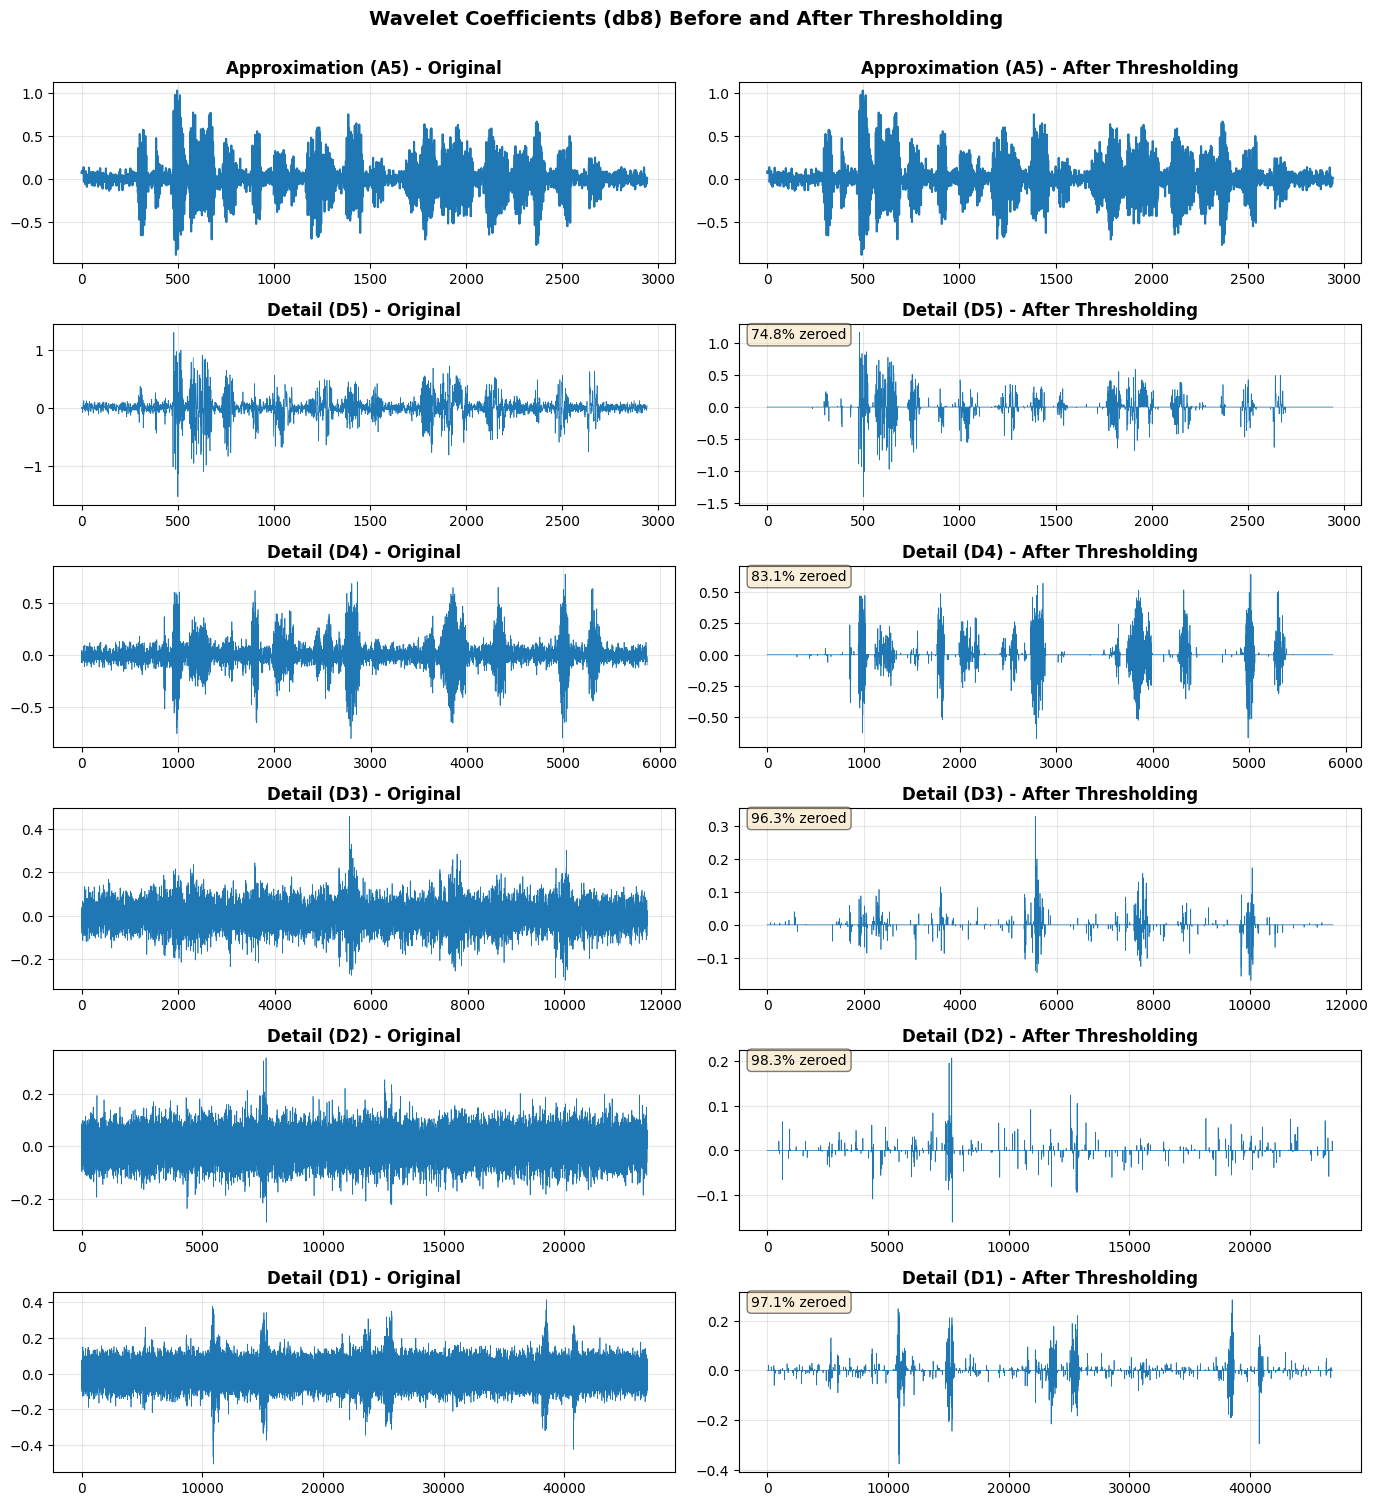

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


def plot_wavelet_coefficients(original_coeffs, thresholded_coeffs, wavelet_name):
    """
    Visualize wavelet coefficients before and after thresholding.
    """
    n_levels = len(original_coeffs) - 1
    
    fig, axes = plt.subplots(n_levels + 1, 2, figsize=(14, 2.5 * (n_levels + 1)))
    
    # Plot approximation coefficients
    axes[0, 0].plot(original_coeffs[0])
    axes[0, 0].set_title(f"Approximation (A{n_levels}) - Original", fontweight='bold')
    axes[0, 0].grid(True, alpha=0.3)
    
    axes[0, 1].plot(thresholded_coeffs[0])
    axes[0, 1].set_title(f"Approximation (A{n_levels}) - After Thresholding", fontweight='bold')
    axes[0, 1].grid(True, alpha=0.3)
    
    # Plot detail coefficients
    for i in range(1, len(original_coeffs)):
        level = n_levels - i + 1
        
        axes[i, 0].plot(original_coeffs[i], linewidth=0.5)
        axes[i, 0].set_title(f"Detail (D{level}) - Original", fontweight='bold')
        axes[i, 0].grid(True, alpha=0.3)
        
        axes[i, 1].plot(thresholded_coeffs[i], linewidth=0.5)
        axes[i, 1].set_title(f"Detail (D{level}) - After Thresholding", fontweight='bold')
        axes[i, 1].grid(True, alpha=0.3)
        
        # Add percentage of coefficients set to zero
        zero_percent = np.sum(thresholded_coeffs[i] == 0) / len(thresholded_coeffs[i]) * 100
        axes[i, 1].text(0.02, 0.98, f"{zero_percent:.1f}% zeroed", 
                       transform=axes[i, 1].transAxes,
                       verticalalignment='top',
                       bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    
    plt.suptitle(f"Wavelet Coefficients ({wavelet_name}) Before and After Thresholding", 
                 fontsize=14, fontweight='bold', y=1.001)
    plt.tight_layout()
    plt.savefig("./output/wavelet_coefficients.png", dpi=300, bbox_inches='tight')
    plt.show()

# Plot the coefficients
plot_wavelet_coefficients(original_coeffs, thresholded_coeffs, 'db8')

### 4.5.4 Comparison with Traditional Methods

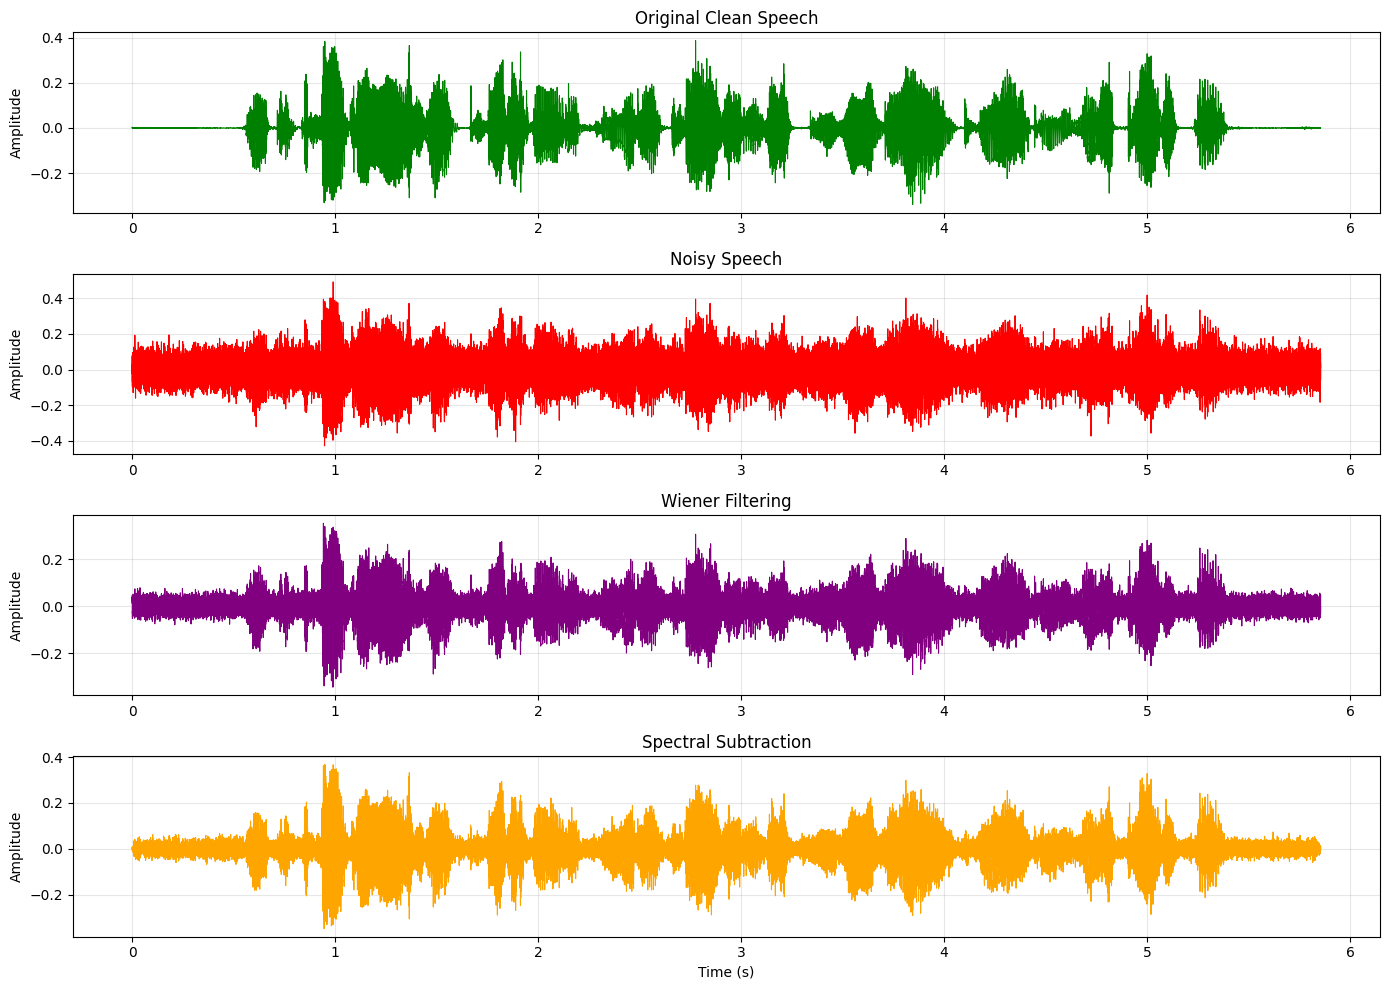

Traditional methods applied successfully!


In [ ]:
import os
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from scipy import signal as scipy_signal


# ----------------------------
# 1. Wiener Filter
# ----------------------------
def wiener_filter(noisy_signal, noise_estimate=None):
    """
    Apply Wiener filtering for speech denoising.
    """
    if noise_estimate is None:
        noise_segment = noisy_signal[:len(noisy_signal)//10]
        noise_spectrum = np.abs(np.fft.rfft(noise_segment))**2
    else:
        noise_spectrum = np.abs(np.fft.rfft(noise_estimate))**2

    signal_spectrum = np.fft.rfft(noisy_signal)
    signal_power = np.abs(signal_spectrum)**2

    wiener_gain = np.maximum(1 - noise_spectrum / (signal_power + 1e-10), 0)
    filtered_spectrum = signal_spectrum * wiener_gain
    denoised = np.fft.irfft(filtered_spectrum, n=len(noisy_signal))

    return denoised


# ----------------------------
# 2. Spectral Subtraction
# ----------------------------
def spectral_subtraction(noisy_signal, noise_estimate=None, alpha=2.0, beta=0.01):
    nperseg = 512
    noverlap = nperseg // 2

    f, t, Zxx = scipy_signal.stft(noisy_signal, fs=sr, 
                                  nperseg=nperseg, noverlap=noverlap)

    if noise_estimate is None:
        noise_frames = Zxx[:, :10]
        noise_spectrum = np.mean(np.abs(noise_frames)**2, axis=1, keepdims=True)
    else:
        _, _, Zxx_noise = scipy_signal.stft(noise_estimate, fs=sr,
                                            nperseg=nperseg, noverlap=noverlap)
        noise_spectrum = np.mean(np.abs(Zxx_noise)**2, axis=1, keepdims=True)

    signal_power = np.abs(Zxx)**2
    enhanced_power = np.maximum(signal_power - alpha * noise_spectrum,
                                beta * signal_power)

    phase = np.angle(Zxx)
    enhanced_spectrum = np.sqrt(enhanced_power) * np.exp(1j * phase)

    _, denoised = scipy_signal.istft(enhanced_spectrum, fs=sr,
                                     nperseg=nperseg, noverlap=noverlap)

    if len(denoised) > len(noisy_signal):
        denoised = denoised[:len(noisy_signal)]

    return denoised


# ----------------------------
# Load clean + noisy speech
# ----------------------------
clean_speech, sr = sf.read("./data/clean_speech.wav", dtype="float32")
noisy_speech, _ = sf.read("./data/noisy_speech.wav", dtype="float32")

# If you want the noise separately (difference between noisy and clean)
noise = noisy_speech - clean_speech

# ----------------------------
# Apply methods
# ----------------------------

denoised_wiener = wiener_filter(noisy_speech, noise)
sf.write("./data/denoised_wiener.wav", denoised_wiener, sr)

denoised_spectral = spectral_subtraction(noisy_speech, noise)
sf.write("./data/denoised_spectral.wav", denoised_spectral, sr)

# ----------------------------
# Visualization
# ----------------------------
fig, axes = plt.subplots(4, 1, figsize=(14, 10))
time_axis = np.arange(len(clean_speech)) / sr

axes[0].plot(time_axis, clean_speech, color='green', linewidth=0.8)
axes[0].set_title("Original Clean Speech")

axes[1].plot(time_axis, noisy_speech, color='red', linewidth=0.8)
axes[1].set_title("Noisy Speech")

axes[2].plot(time_axis, denoised_wiener, color='purple', linewidth=0.8)
axes[2].set_title("Wiener Filtering")

axes[3].plot(time_axis, denoised_spectral, color='orange', linewidth=0.8)
axes[3].set_title("Spectral Subtraction")

for ax in axes:
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (s)")

plt.tight_layout()
plt.savefig("./output/denoising_methods_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print("Traditional methods applied successfully!")


### 4.5.5 Evaluation


EVALUATION METRICS

Input Signal (Noisy): SNR=1.85 dB, MSE=0.002505

----------------------------------------------------------------------
Wavelet Denoising: SNR=6.90 dB (Δ=+5.05), MSE=0.000784
Wiener Filtering: SNR=3.65 dB (Δ=+1.80), MSE=0.001654
Spectral Subtraction: SNR=6.37 dB (Δ=+4.52), MSE=0.000884



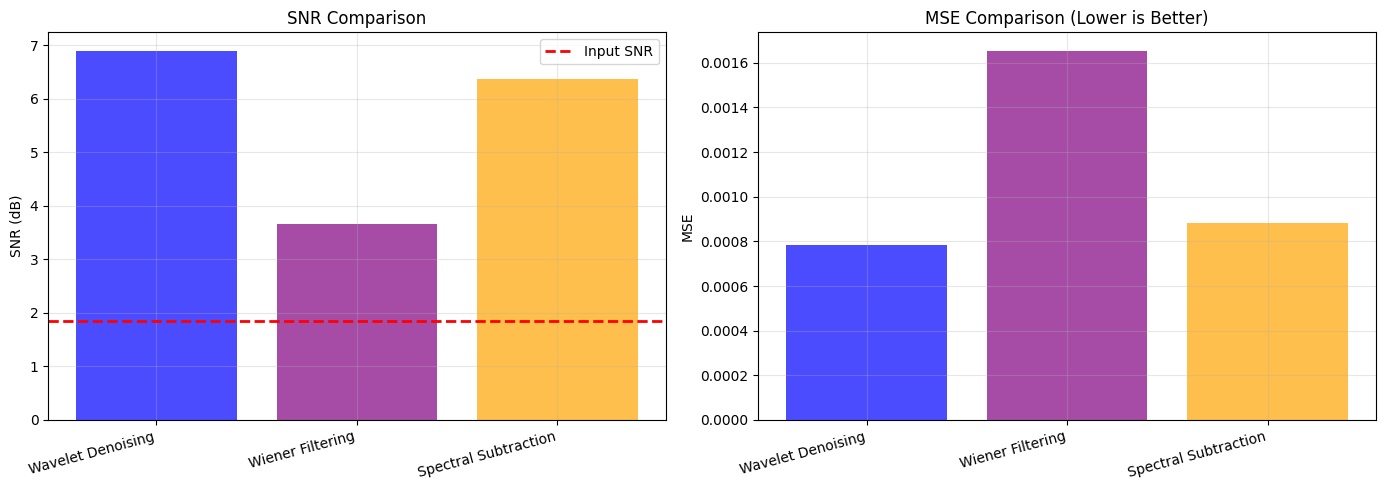

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import os
import soundfile as sf
import pywt
from scipy import signal as scipy_signal

# ----------------------------
# Helper functions
# ----------------------------
def align_signal_length(signal, target_len):
    """Trim or pad a signal to a target length."""
    if len(signal) > target_len:
        return signal[:target_len]
    elif len(signal) < target_len:
        return np.pad(signal, (0, target_len - len(signal)))
    return signal

def match_rms(reference, signal):
    """Match RMS amplitude of `signal` to `reference`."""
    rms_ref = np.sqrt(np.mean(reference**2))
    rms_sig = np.sqrt(np.mean(signal**2))
    return signal * (rms_ref / (rms_sig + 1e-10))

def wavelet_denoise(signal_data, wavelet='db8', level=5, threshold_multiplier=0.2):
    """Wavelet-based denoising."""
    coeffs = pywt.wavedec(signal_data, wavelet, level=level)
    sigma = np.median(np.abs(coeffs[-1])) / 0.6745
    threshold = threshold_multiplier * sigma * np.sqrt(2 * np.log(len(signal_data)))
    coeffs_thresh = [coeffs[0]] + [pywt.threshold(c, threshold, mode='soft') for c in coeffs[1:]]
    denoised = pywt.waverec(coeffs_thresh, wavelet)
    denoised = align_signal_length(denoised, len(signal_data))
    denoised /= (np.max(np.abs(denoised)) + 1e-8)
    return denoised.astype(np.float32)

def wiener_filter_fixed(noisy_signal, noise_estimate=None):
    """Frequency-domain Wiener filter (fixed)."""
    noisy_signal = np.asarray(noisy_signal, dtype=np.float32)
    N = len(noisy_signal)
    S = np.fft.rfft(noisy_signal)
    signal_power = np.abs(S)**2

    if noise_estimate is None:
        n_samples = max(1, N // 20)  # first 5% as noise
        noise = noisy_signal[:n_samples]
    else:
        noise = noise_estimate[:N]

    noise = align_signal_length(noise, N)
    noise_power = np.abs(np.fft.rfft(noise))**2

    wiener_gain = np.maximum(1 - noise_power / (signal_power + 1e-10), 0)
    S_filtered = S * wiener_gain
    denoised = np.fft.irfft(S_filtered, n=N)
    return denoised.astype(np.float32)

def spectral_subtraction(noisy_signal, sample_rate, alpha=4.0, beta=0.002):
    """Basic spectral subtraction denoising."""
    f, t, Zxx = scipy_signal.stft(noisy_signal, fs=sample_rate, nperseg=512, noverlap=256)
    magnitude = np.abs(Zxx)
    phase = np.angle(Zxx)
    noise_mag = np.mean(magnitude[:, :int(0.05*Zxx.shape[1])], axis=1, keepdims=True)
    subtracted = np.maximum(magnitude - alpha * noise_mag, beta * noise_mag)
    Zxx_denoised = subtracted * np.exp(1j * phase)
    _, denoised = scipy_signal.istft(Zxx_denoised, fs=sample_rate, nperseg=512, noverlap=256)
    return denoised.astype(np.float32)

def calculate_snr(clean, denoised):
    signal_power = np.sum(clean ** 2)
    noise_power = np.sum((clean - denoised) ** 2)
    return float('inf') if noise_power == 0 else 10 * np.log10(signal_power / noise_power)

def calculate_mse(clean, denoised):
    return np.mean((clean - denoised) ** 2)

def calculate_metrics(clean, noisy, denoised_signals, method_names):
    print("\n" + "="*70)
    print("EVALUATION METRICS")
    print("="*70)
    input_snr = calculate_snr(clean, noisy)
    print(f"\nInput Signal (Noisy): SNR={input_snr:.2f} dB, MSE={calculate_mse(clean, noisy):.6f}")
    print("\n" + "-"*70)

    results = []
    for name, sig in zip(method_names, denoised_signals):
        snr = calculate_snr(clean, sig)
        mse = calculate_mse(clean, sig)
        results.append({'method': name, 'snr': snr, 'mse': mse, 'snr_improvement': snr - input_snr})
        print(f"{name}: SNR={snr:.2f} dB (Δ={snr - input_snr:+.2f}), MSE={mse:.6f}")
    print("\n" + "="*70)
    return results

# ----------------------------
# Apply denoising
# ----------------------------
sample_rate = 16000

denoised_wavelet = wavelet_denoise(noisy_speech)
denoised_wavelet = match_rms(clean_speech, denoised_wavelet)

denoised_wiener = wiener_filter_fixed(noisy_speech)
denoised_wiener = align_signal_length(denoised_wiener, len(clean_speech))
denoised_wiener = match_rms(clean_speech, denoised_wiener)

denoised_spectral = spectral_subtraction(noisy_speech, sample_rate)
denoised_spectral = align_signal_length(denoised_spectral, len(clean_speech))
denoised_spectral = match_rms(clean_speech, denoised_spectral)

# Save audio
os.makedirs("./output", exist_ok=True)
sf.write("./output/denoised_wavelet.wav", denoised_wavelet, sample_rate)
sf.write("./output/denoised_wiener.wav", denoised_wiener, sample_rate)
sf.write("./output/denoised_spectral.wav", denoised_spectral, sample_rate)

# ----------------------------
# Metrics and Visualization
# ----------------------------
method_names = ["Wavelet Denoising", "Wiener Filtering", "Spectral Subtraction"]
denoised_signals = [denoised_wavelet, denoised_wiener, denoised_spectral]

results = calculate_metrics(clean_speech, noisy_speech, denoised_signals, method_names)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# SNR comparison
snr_values = [r['snr'] for r in results]
axes[0].bar(range(len(method_names)), snr_values, color=['blue', 'purple', 'orange'], alpha=0.7)
axes[0].axhline(calculate_snr(clean_speech, noisy_speech), color='red', linestyle='--', linewidth=2, label='Input SNR')
axes[0].set_xticks(range(len(method_names)))
axes[0].set_xticklabels(method_names, rotation=15, ha='right')
axes[0].set_ylabel("SNR (dB)")
axes[0].set_title("SNR Comparison")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# MSE comparison
mse_values = [r['mse'] for r in results]
axes[1].bar(range(len(method_names)), mse_values, color=['blue', 'purple', 'orange'], alpha=0.7)
axes[1].set_xticks(range(len(method_names)))
axes[1].set_xticklabels(method_names, rotation=15, ha='right')
axes[1].set_ylabel("MSE")
axes[1].set_title("MSE Comparison (Lower is Better)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("./output/metrics_comparison.png", dpi=300, bbox_inches='tight')
plt.show()


### 4.5.6 Spectrogram Analysis


Generating spectrograms...


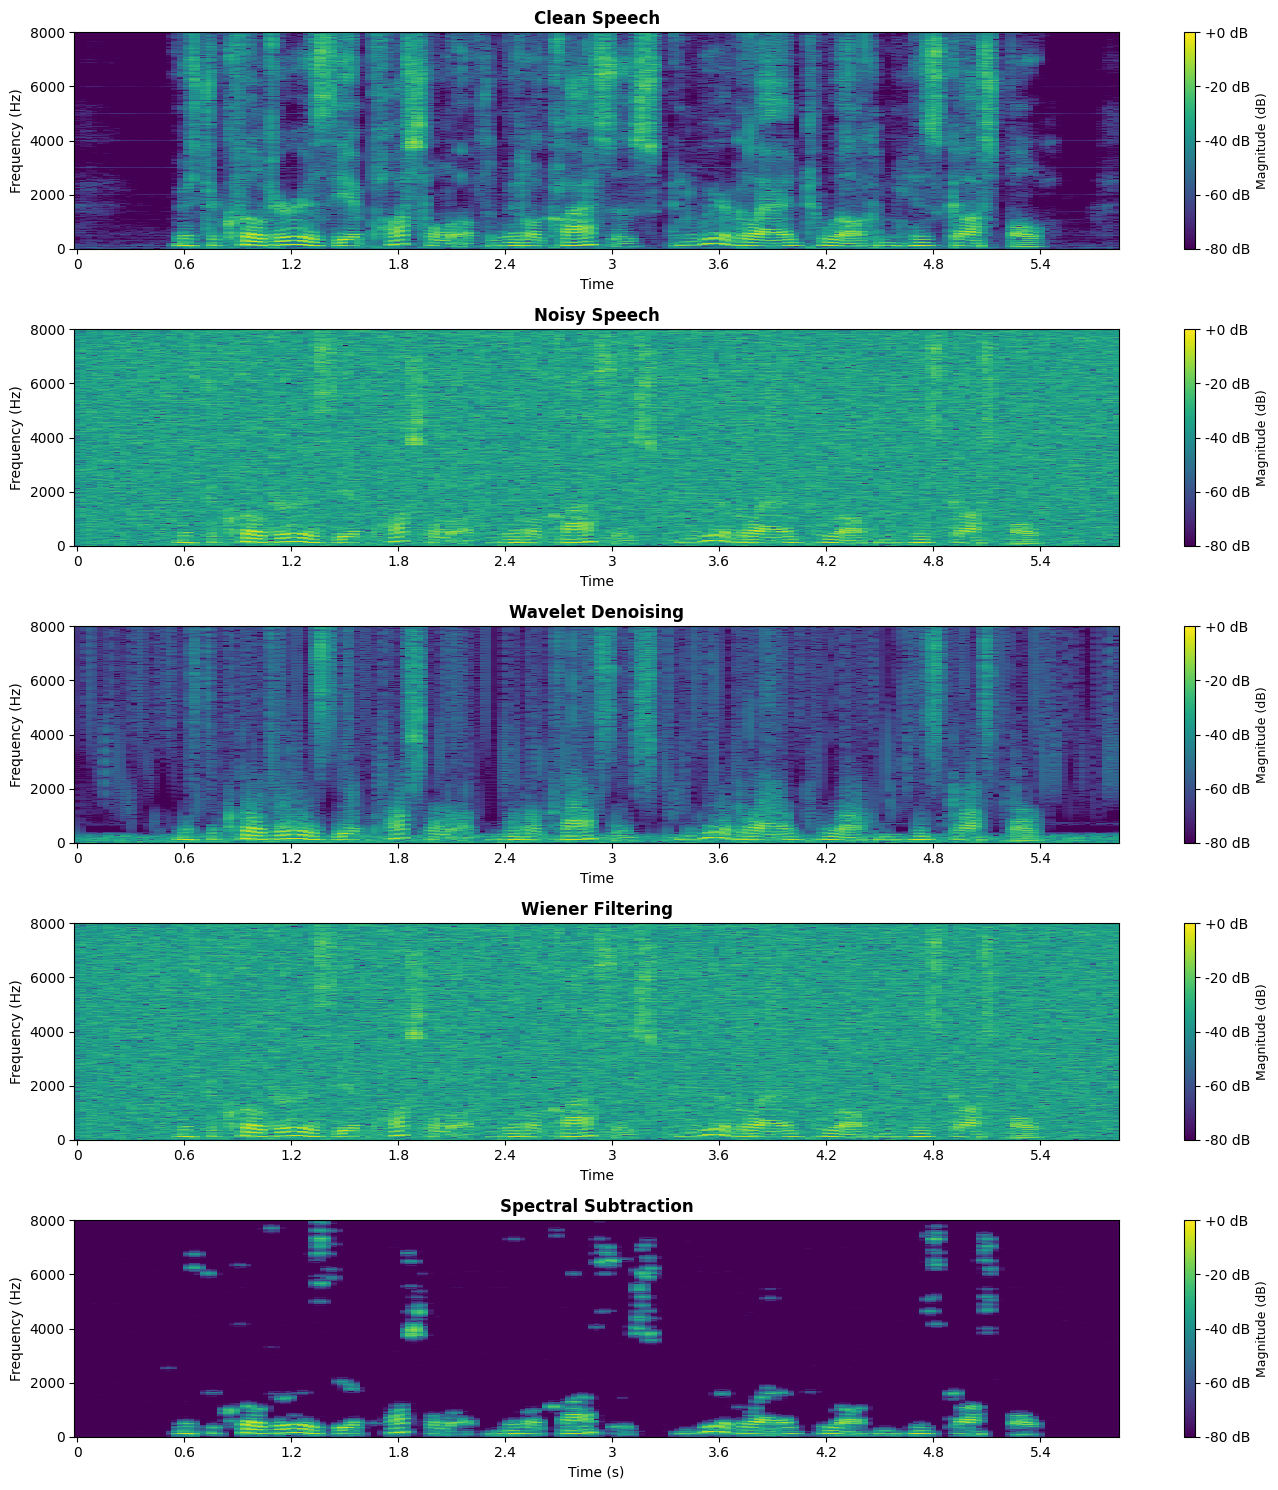

In [ ]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt

def plot_spectrograms(signals, titles, sr, n_fft=2048, hop_length=512):
    """
    Plot spectrograms for multiple signals.
    """
    n_signals = len(signals)
    fig, axes = plt.subplots(n_signals, 1, figsize=(14, 3*n_signals))
    
    if n_signals == 1:
        axes = [axes]
    
    for idx, (sig, title) in enumerate(zip(signals, titles)):
        D = librosa.amplitude_to_db(np.abs(librosa.stft(sig, n_fft=n_fft, 
                                                         hop_length=hop_length)), 
                                    ref=np.max)
        img = librosa.display.specshow(D, sr=sr, hop_length=hop_length, 
                                       x_axis='time', y_axis='hz', 
                                       ax=axes[idx], cmap='viridis')
        axes[idx].set_title(title, fontsize=12, fontweight='bold')
        axes[idx].set_ylabel("Frequency (Hz)", fontsize=10)
        
        if idx == n_signals - 1:
            axes[idx].set_xlabel("Time (s)", fontsize=10)
        
        # Add colorbar
        cbar = fig.colorbar(img, ax=axes[idx], format='%+2.0f dB')
        cbar.set_label('Magnitude (dB)', fontsize=9)
    
    plt.tight_layout()
    plt.savefig("./output/spectrograms_comparison.png", dpi=300, bbox_inches='tight')
    plt.show()

# Generate spectrograms
print("\nGenerating spectrograms...")
signals_to_plot = [clean_speech, noisy_speech, denoised_wavelet, 
                   denoised_wiener, denoised_spectral]
titles_to_plot = ["Clean Speech", "Noisy Speech", "Wavelet Denoising",
                  "Wiener Filtering", "Spectral Subtraction"]

plot_spectrograms(signals_to_plot, titles_to_plot, sr)

### 4.5.7 Application to Speech Recognition

In [42]:
# ASR using OpenAI Whisper (small model)
try:
    import whisper
    import soundfile as sf
    import numpy as np
    import os

    print("\nLoading Whisper ASR...")

    # Load Whisper model (small is a good balance of speed and accuracy)
    model = whisper.load_model("medium")

    def transcribe_with_whisper(audio_array, sample_rate=16000):
        """
        Transcribe audio using Whisper.
        Args:
            audio_array: numpy array of audio samples
            sample_rate: int, sample rate of audio
        Returns:
            str: transcribed text
        """
        temp_file = "temp_asr.wav"
        sf.write(temp_file, audio_array, sample_rate)

        try:
            result = model.transcribe(temp_file)
            text = result["text"].strip()
        except Exception as e:
            text = f"[ASR Error: {e}]"
        finally:
            if os.path.exists(temp_file):
                os.remove(temp_file)

        return text

    # Define audio signals
    test_signals = {
        "Clean": clean_speech,
        "Noisy": noisy_speech,
        "Wavelet Denoised": denoised_wavelet,
        "Wiener Filtered": denoised_wiener,
        "Spectral Subtracted": denoised_spectral
    }

    # Sample rate
    sample_rate = 16000  # Hz

    print("\n" + "="*70)
    print("AUTOMATIC SPEECH RECOGNITION RESULTS (Whisper Medium)")
    print("="*70)

    for name, sig in test_signals.items():
        try:
            transcription = transcribe_with_whisper(sig, sample_rate)
            print(f"\n{name}:")
            print(f"  Transcription: \"{transcription}\"")
        except Exception as e:
            print(f"\n{name}:")
            print(f"  Error: {str(e)}")

    print("\n" + "="*70)

except ImportError:
    print("\nNote: whisper library not available.")
    print("Install with: pip install openai-whisper soundfile")
    print("ASR evaluation skipped.")
except Exception as e:
    print(f"\nASR evaluation error: {str(e)}")



Loading Whisper ASR...

AUTOMATIC SPEECH RECOGNITION RESULTS (Whisper Medium)


e:\project-workspace\jupyter-books\wavelet-book\.venv\Lib\site-packages\whisper\transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")



Clean:
  Transcription: "Mr. Quilter is the apostle of the middle classes and we are glad to welcome his gospel."

Noisy:
  Transcription: "Mr. Quilter is the apostle of the middle classes. We are glad to welcome him to his gospel."

Wavelet Denoised:
  Transcription: "Mr. Quilter is the apostle of the middle classes. We are glad to welcome him to his gospel."

Wiener Filtered:
  Transcription: "Mr. Quilter is the apostle of the middle classes. We are glad to welcome him to his gospel."

Spectral Subtracted:
  Transcription: "Mr. Quilter is the apostle of the middle classes, and we are glad to welcome him to his gospel."



### 4.5.8 Experimentation with Different Wavelets

In [ ]:
import pywt
import numpy as np
import matplotlib.pyplot as plt
import os

def align_signal_length(signal, target_length):
    """Ensure the denoised signal matches original length."""
    if len(signal) > target_length:
        return signal[:target_length]
    elif len(signal) < target_length:
        return np.pad(signal, (0, target_length - len(signal)), mode='constant')
    return signal

def compute_metrics(clean, denoised):
    """Return SNR (dB) and MSE."""
    mse = np.mean((clean - denoised) ** 2)
    signal_power = np.mean(clean ** 2)
    snr = 10 * np.log10(signal_power / mse) if mse > 0 else float("inf")
    return snr, mse

def sure_threshold(coeffs_detail):
    """
    Calculate optimal threshold for a single detail level using SURE.
    Returns the threshold that minimizes Stein's Unbiased Risk Estimate.
    """
    if len(coeffs_detail) == 0:
        return 0
    
    # Estimate noise level
    sigma = np.median(np.abs(coeffs_detail)) / 0.6745
    
    if sigma < 1e-10:  # Nearly no noise
        return 0
    
    # Normalize coefficients
    coeffs_norm = coeffs_detail / sigma
    n = len(coeffs_norm)
    
    # Create candidate thresholds
    abs_coeffs = np.abs(coeffs_norm)
    thresholds = np.linspace(0, max(3, np.max(abs_coeffs)), 100)
    
    risks = []
    for t in thresholds:
        # Soft threshold
        thresh_coeffs = np.sign(coeffs_norm) * np.maximum(abs_coeffs - t, 0)
        
        # SURE risk estimate
        risk = (n - 2 * np.sum(abs_coeffs <= t) + 
                np.sum(np.minimum(abs_coeffs, t)**2))
        risks.append(risk)
    
    # Find minimum risk threshold
    optimal_idx = np.argmin(risks)
    optimal_threshold = thresholds[optimal_idx] * sigma
    
    return optimal_threshold

def wavelet_denoise_auto(signal_data, wavelet='db8', level=5, method='universal', verbose=False):
    """
    Denoise with different shrinkage rules (universal, sure, minimax).
    Now with proper per-level SURE implementation.
    """
    coeffs = pywt.wavedec(signal_data, wavelet, level=level)
    
    # Estimate noise from finest detail level
    sigma = np.median(np.abs(coeffs[-1])) / 0.6745
    
    if method == 'universal':  # VisuShrink
        threshold = sigma * np.sqrt(2 * np.log(len(signal_data)))
        coeffs_thresh = [coeffs[0]] + [pywt.threshold(c, threshold, mode='soft') 
                                        for c in coeffs[1:]]
        if verbose:
            print(f"    {wavelet} Universal: threshold={threshold:.6f}")
    
    elif method == 'sure':  # SURE Shrink - per-level optimization
        coeffs_thresh = [coeffs[0]]  # Keep approximation
        thresholds_used = []
        
        for i, detail in enumerate(coeffs[1:], 1):
            optimal_t = sure_threshold(detail)
            thresholds_used.append(optimal_t)
            coeffs_thresh.append(pywt.threshold(detail, optimal_t, mode='soft'))
        
        if verbose:
            print(f"    {wavelet} SURE: thresholds={[f'{t:.6f}' for t in thresholds_used]}")
    
    elif method == 'minimax':
        # Minimax threshold (Donoho & Johnstone)
        n = len(signal_data)
        if n > 32:
            threshold = sigma * (0.3936 + 0.1829 * np.log2(n))
        else:
            threshold = 0  # For very short signals
        
        coeffs_thresh = [coeffs[0]] + [pywt.threshold(c, threshold, mode='soft') 
                                        for c in coeffs[1:]]
        if verbose:
            print(f"    {wavelet} Minimax: threshold={threshold:.6f}")
    
    else:
        raise ValueError(f"Unknown method: {method}")
    
    denoised = pywt.waverec(coeffs_thresh, wavelet)
    return align_signal_length(denoised, len(signal_data)).astype(np.float32)

def compare_wavelets(clean, noisy, wavelets=None, verbose=False):
    """
    Compare different wavelets across shrinkage methods.
    Returns dictionary of results for each wavelet.
    """
    if wavelets is None:
        wavelets = ['db4', 'db8', 'sym4', 'sym8', 'coif5', 'bior3.5', 'dmey']
    
    methods = ['universal', 'sure', 'minimax']
    
    print("="*70)
    print("WAVELET COMPARISON (Best across shrinkage rules)")
    print("="*70)
    print("Valid wavelets to test:", wavelets, "\n")
    
    results = {}
    for w in wavelets:
        best_snr, best_mse, best_method, best_signal = -np.inf, np.inf, None, None
        
        if verbose:
            print(f"\n{w}:")
        
        for m in methods:
            den = wavelet_denoise_auto(noisy, wavelet=w, level=5, method=m, verbose=verbose)
            snr, mse = compute_metrics(clean, den)
            
            if verbose:
                print(f"      {m}: SNR={snr:.2f} dB, MSE={mse:.6f}")
            
            if snr > best_snr:
                best_snr, best_mse, best_method, best_signal = snr, mse, m, den
        
        results[w] = {
            'snr': best_snr,
            'mse': best_mse,
            'method': best_method,
            'signal': best_signal
        }
        
        if not verbose:
            print(f"{w:8s}: SNR={best_snr:.2f} dB, MSE={best_mse:.6f} (best={best_method})")
    
    print("\n" + "="*70)
    return results

# ----------------------------
# Run comparison
# ----------------------------
# wavelets_to_test = ['db4', 'db8', 'sym4', 'sym8', 'coif5', 'bior3.5', 'dmey']
# wavelet_results = compare_wavelets(clean_speech, noisy_speech, 
#                                    wavelets=wavelets_to_test, 
#                                    verbose=False)  # Set True for details

# ----------------------------
# Visualize denoised signals
# ----------------------------
def visualize_results(wavelet_results, clean_speech, sample_rate):
    """
    Create visualization plots for wavelet comparison results.
    """
    num_wavelets = len(wavelet_results)
    if num_wavelets == 0:
        print("No valid wavelet results to display.")
        return
    
    # Plot 1: Denoised signal waveforms
    fig, axes = plt.subplots(num_wavelets, 1, figsize=(14, 2.5*num_wavelets))
    if num_wavelets == 1:
        axes = [axes]
    
    time_axis = np.arange(len(clean_speech)) / sample_rate
    
    for idx, (wavelet_name, data) in enumerate(wavelet_results.items()):
        axes[idx].plot(time_axis, data['signal'], linewidth=0.8)
        axes[idx].set_title(
            f"{wavelet_name} (SNR: {data['snr']:.2f} dB, MSE: {data['mse']:.6f}, Method: {data['method']})",
            fontsize=11, fontweight='bold'
        )
        axes[idx].set_ylabel("Amplitude")
        axes[idx].grid(True, alpha=0.3)
        if idx == num_wavelets - 1:
            axes[idx].set_xlabel("Time (s)")
    
    plt.suptitle("Denoising Results with Different Wavelet Types", 
                 fontsize=13, fontweight='bold', y=1.001)
    plt.tight_layout()
    os.makedirs("output", exist_ok=True)
    plt.savefig("output/wavelet_types_comparison.png", dpi=300, bbox_inches='tight')
    plt.show()
    
    # Plot 2: Performance summary (SNR and MSE)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    wavelets = list(wavelet_results.keys())
    snr_vals = [wavelet_results[w]['snr'] for w in wavelets]
    mse_vals = [wavelet_results[w]['mse'] for w in wavelets]
    colors = plt.cm.viridis(np.linspace(0, 0.9, len(wavelets)))
    
    # SNR comparison
    ax1.barh(wavelets, snr_vals, color=colors, alpha=0.8)
    ax1.set_xlabel("SNR (dB)", fontsize=11, fontweight='bold')
    ax1.set_title("SNR by Wavelet Type", fontsize=12, fontweight='bold')
    ax1.grid(True, alpha=0.3, axis='x')
    
    # Add value labels
    for i, (w, snr) in enumerate(zip(wavelets, snr_vals)):
        ax1.text(snr + 0.1, i, f'{snr:.2f}', va='center', fontsize=9)
    
    # MSE comparison
    ax2.barh(wavelets, mse_vals, color=colors, alpha=0.8)
    ax2.set_xlabel("MSE", fontsize=11, fontweight='bold')
    ax2.set_title("MSE by Wavelet Type", fontsize=12, fontweight='bold')
    ax2.grid(True, alpha=0.3, axis='x')
    
    # Add value labels
    for i, (w, mse) in enumerate(zip(wavelets, mse_vals)):
        ax2.text(mse + 0.00002, i, f'{mse:.6f}', va='center', fontsize=9)
    
    plt.tight_layout()
    plt.savefig("output/wavelet_performance_summary.png", dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\n✓ Plots saved to 'output/' directory")

# Example usage:
"""
# After running comparison:
wavelet_results = compare_wavelets(clean_speech, noisy_speech)
visualize_results(wavelet_results, clean_speech, sample_rate)
"""

'\n# After running comparison:\nwavelet_results = compare_wavelets(clean_speech, noisy_speech)\nvisualize_results(wavelet_results, clean_speech, sample_rate)\n'

WAVELET COMPARISON (Best across shrinkage rules)
Valid wavelets to test: ['db4', 'db8', 'sym4', 'sym8', 'coif5', 'bior3.5', 'dmey'] 

db4     : SNR=7.38 dB, MSE=0.000701 (best=sure)
db8     : SNR=7.51 dB, MSE=0.000681 (best=sure)
sym4    : SNR=7.31 dB, MSE=0.000713 (best=sure)
sym8    : SNR=7.60 dB, MSE=0.000666 (best=sure)
coif5   : SNR=7.61 dB, MSE=0.000665 (best=sure)
bior3.5 : SNR=6.35 dB, MSE=0.000890 (best=sure)
dmey    : SNR=7.54 dB, MSE=0.000676 (best=sure)



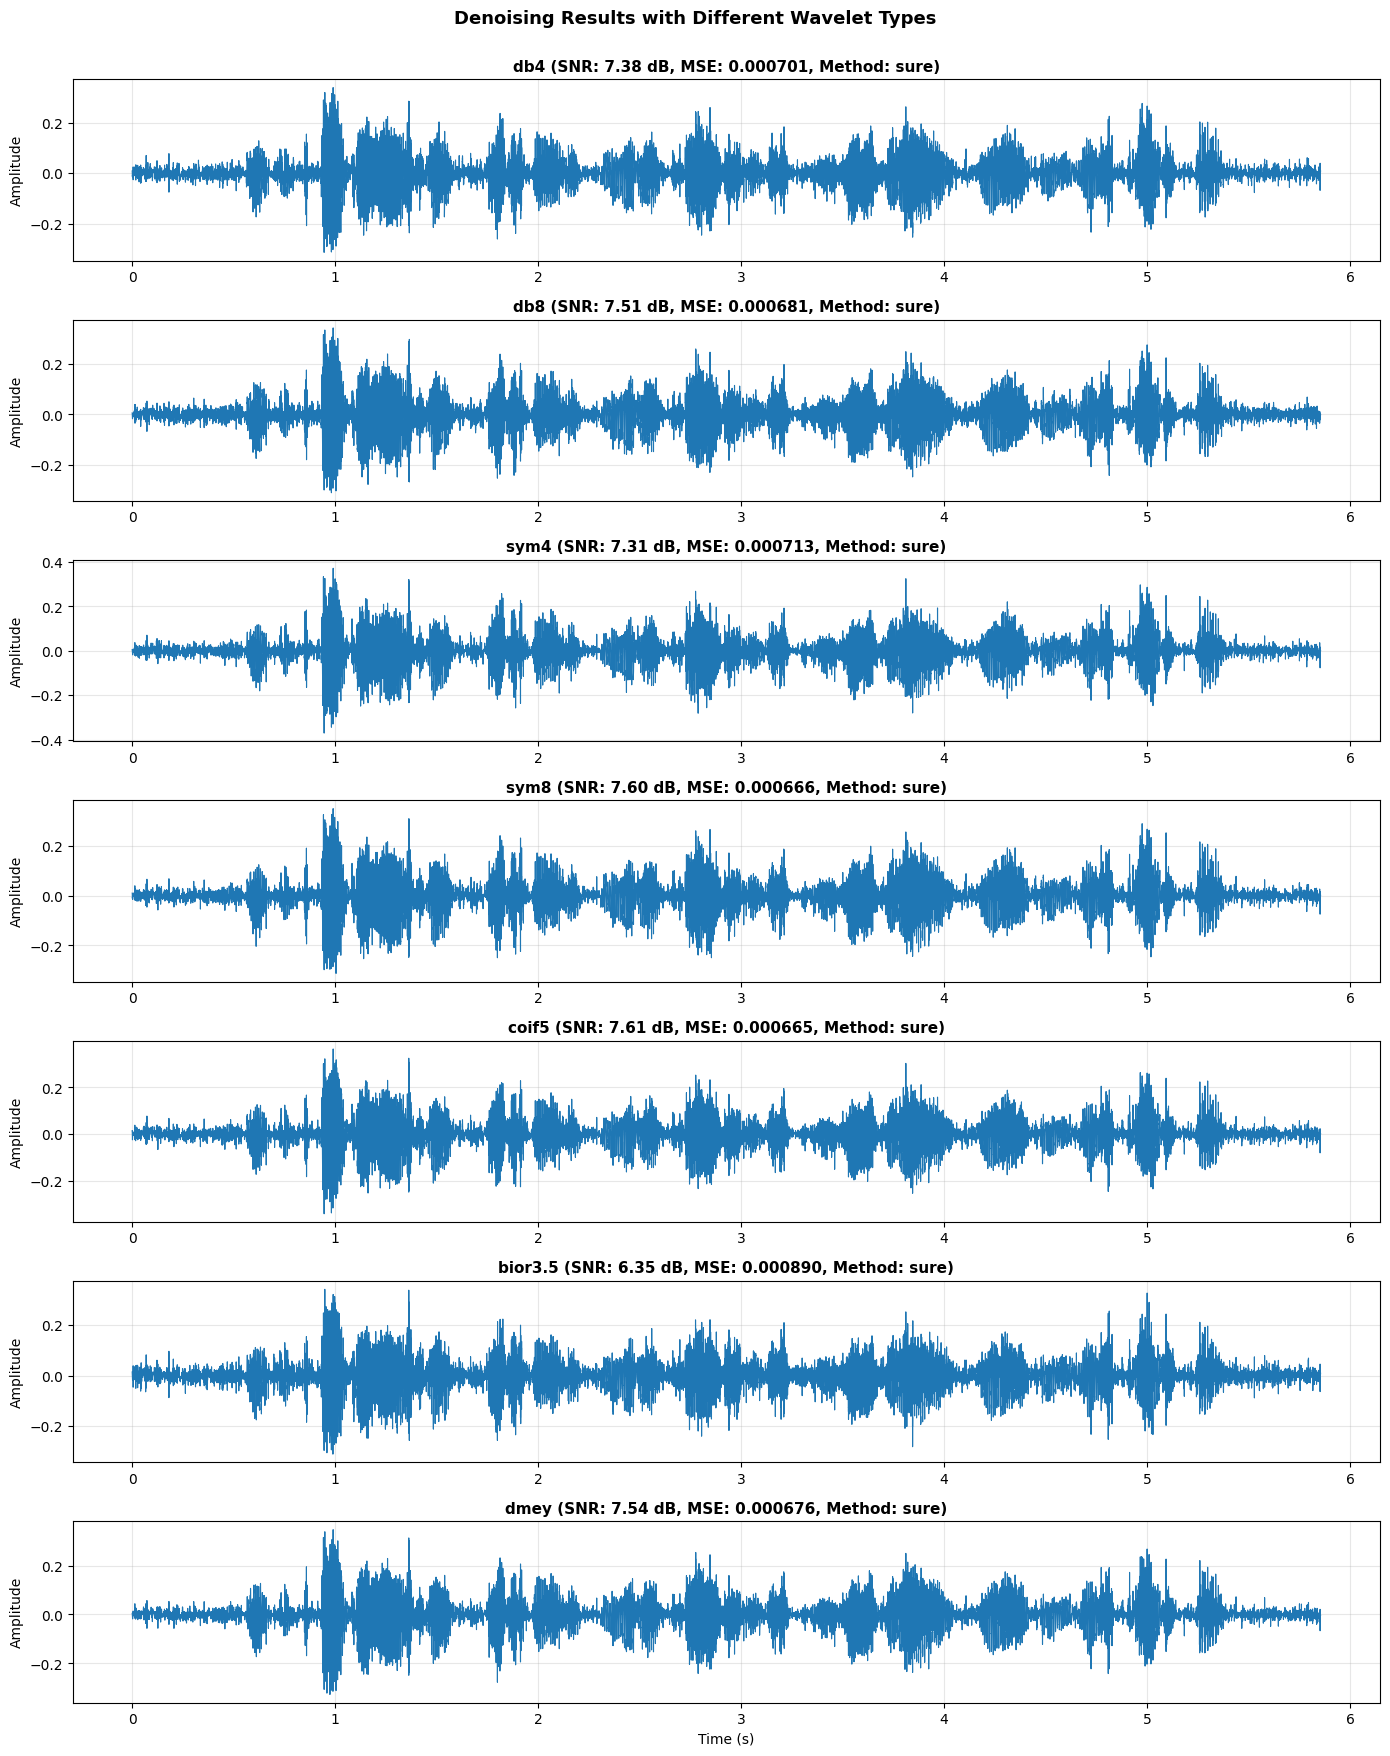

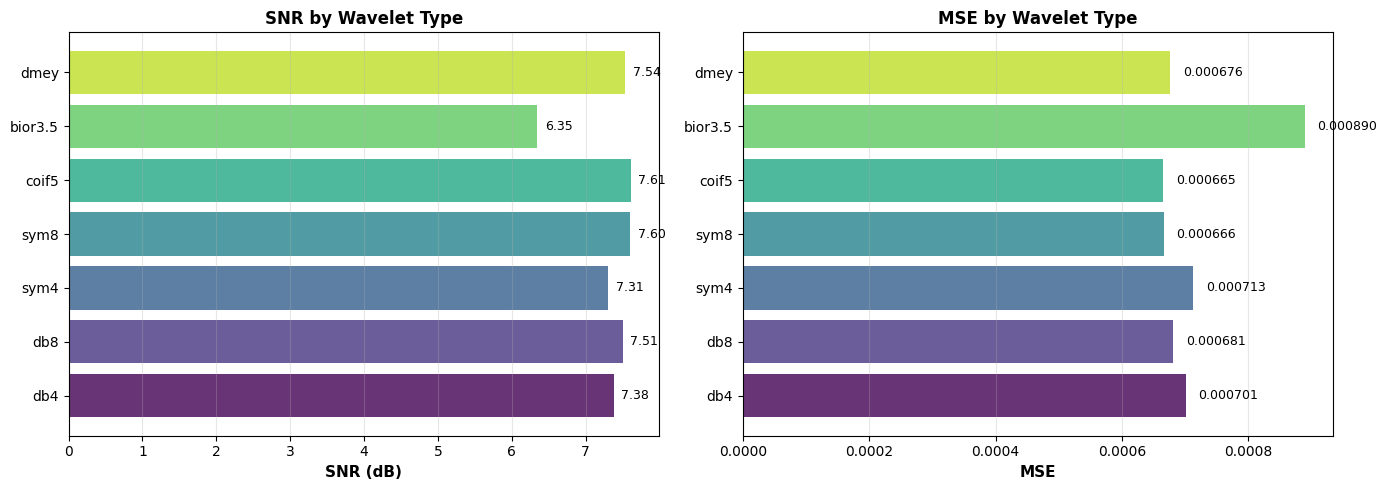


✓ Plots saved to 'output/' directory


In [75]:
# Example usage:

# After running comparison:
wavelet_results = compare_wavelets(clean_speech, noisy_speech)
visualize_results(wavelet_results, clean_speech, sample_rate)